# Chapitre 11 - Cours 5 : les sorties des jobs et les cas d'usage

À quoi sert un job de lots, et que fait-on de ce qu'il produit ? Ce n'est presque jamais
un rapport destiné à un humain : c'est une structure de données (un index, une table de
recommandations, un modèle) qu'un système en ligne va servir. Ce cours montre comment
produire ces sorties sans compromettre ni la base de production ni la capacité à
corriger une erreur. Il couvre l'introduction du chapitre (sorties immuables) et la section *Batch Use Cases* (*Extract-Transform-Load*, *Analytics*, *Machine Learning*, *Serving Derived Data*).

**Plan.**

1. La philosophie des sorties : entrées immuables, sorties jetables.
2. Construire un index de recherche par lots.
3. Construire une base clé-valeur par lots plutôt qu'écrire dans la base de production.

4. ETL et analytique : agrégats préparés contre requêtes ad hoc.
5. L'apprentissage automatique : préparer des données d'entraînement.
6. Servir les données dérivées à travers un flux.

In [1]:
import math
import os
import shutil
import sqlite3
import tempfile
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
WORK = tempfile.mkdtemp(prefix="ddia_sorties_")

## 1. La philosophie des sorties (section *Batch Processing*, introduction)

Un job de lots traite son entrée comme **immuable** et produit sa sortie **de zéro**,
sans effet de bord sur des systèmes externes. Le livre en tire plusieurs bénéfices :

- **tolérance aux fautes humaines** : si un déploiement introduit un bogue, on revient à
  l'ancien code et on relance, ou on rebascule sur la sortie précédente, conservée dans
  un autre répertoire ; une base modifiée en place par du code bogué, elle, reste
  corrompue après le retour à l'ancien code ;
- **irréversibilité minimale** : comme une erreur se répare facilement, on peut
  développer plus vite ;
- **relances automatiques** : une tâche en échec est simplement relancée, puisque la
  même entrée donne la même sortie ; les sorties partielles sont jetées ;
- **réutilisation** : les mêmes fichiers d'entrée servent à plusieurs jobs, dont des jobs
  de contrôle qui comparent la sortie à celle de la veille.

Démonstration : un job quotidien calcule le panier moyen par pays. La version 2 du code
contient un bogue (elle compte les montants en centimes). On compare deux architectures :
sorties versionnées publiées par un pointeur atomique, et mise à jour en place d'une
table.

In [2]:
rng = np.random.default_rng(1)
ventes = pd.DataFrame({"pays": rng.choice(["FR", "DE", "US", "JP"], 20_000), "montant": rng.gamma(2, 30, 20_000).round(2)})


def job_v1(df):
    return df.groupby("pays").montant.mean().round(2)


def job_v2_bogue(df):
    return (df.groupby("pays").montant.mean() * 100).round(2)      # bogue : centimes


base = os.path.join(WORK, "panier_moyen")
os.makedirs(base)
journal = []
for version, job in [("v1", job_v1), ("v2", job_v2_bogue)]:
    d_ = os.path.join(base, version)
    os.makedirs(d_)
    job(ventes).to_csv(os.path.join(d_, "part-00000.csv"))
    B.publish_version(base, d_)
    journal.append({"étape": f"déploiement {version}", "version publiée": B.current_version(base),
                    "FR lu par le service": pd.read_csv(os.path.join(base, "current", "part-00000.csv"), index_col=0).loc["FR"].iloc[0]})
B.publish_version(base, os.path.join(base, "v1"))                 # retour arrière : un seul renommage
journal.append({"étape": "retour arrière", "version publiée": B.current_version(base),
                "FR lu par le service": pd.read_csv(os.path.join(base, "current", "part-00000.csv"), index_col=0).loc["FR"].iloc[0]})
# architecture « en place » : la v2 écrase les valeurs de la table de production
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE panier (pays TEXT PRIMARY KEY, moyen REAL)")
for job, lib in [(job_v1, "déploiement v1"), (job_v2_bogue, "déploiement v2"), (job_v1, "retour arrière du code")]:
    if lib != "retour arrière du code":
        con.executemany("INSERT OR REPLACE INTO panier VALUES (?, ?)", list(job(ventes).items()))
    journal.append({"étape": f"[en place] {lib}", "version publiée": "-",
                    "FR lu par le service": con.execute("SELECT moyen FROM panier WHERE pays='FR'").fetchone()[0]})
pd.DataFrame(journal).set_index("étape")

,version publiée,FR lu par le service
étape,,
déploiement v1,v1,60.15
déploiement v2,v2,6014.98
retour arrière,v1,60.15
[en place] déploiement v1,-,60.15
[en place] déploiement v2,-,6014.98
[en place] retour arrière du code,-,6014.98


Avec des sorties versionnées, le retour arrière est un simple changement de pointeur
(`os.replace` d'un lien symbolique, atomique) : le service retrouve instantanément la
bonne valeur. Dans l'architecture en place, revenir à l'ancien **code** ne répare pas
les **données** : il faut relancer un calcul de réparation, et si la sortie avait été
mélangée à d'autres écritures, on ne saurait même plus quoi réparer. (Dans le cas d'un
job incrémental qui modifie la table au lieu de la recalculer, ce serait pire encore.)

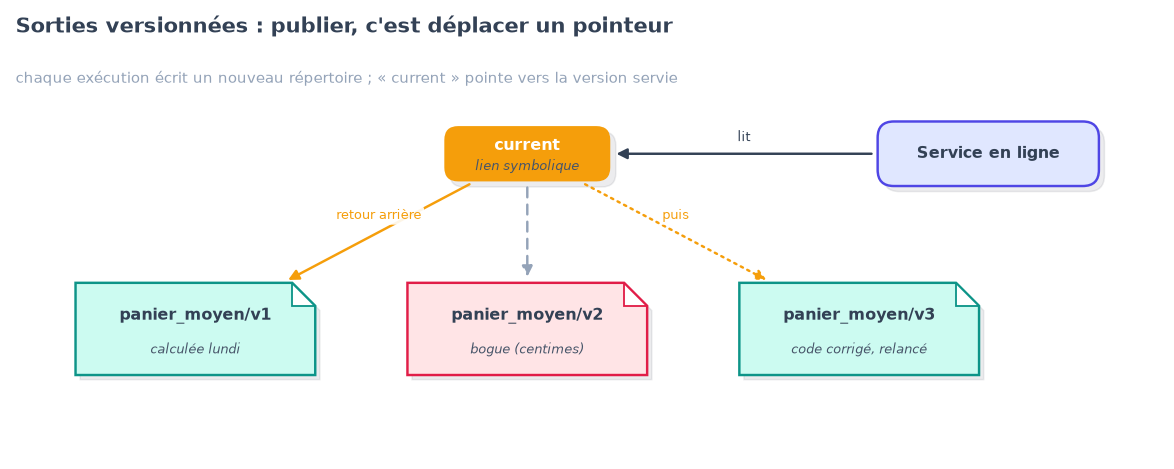

In [3]:
d = Diagram(12.5, 3.9, title="Sorties versionnées : publier, c'est déplacer un pointeur",
            subtitle="chaque exécution écrit un nouveau répertoire ; « current » pointe vers la version servie")
d.box("v1", 2.0, 1.4, "panier_moyen/v1", sub="calculée lundi", color=TEAL, kind="doc", w=2.6, h=1.0)
d.box("v2", 5.6, 1.4, "panier_moyen/v2", sub="bogue (centimes)", color=ROSE, kind="doc", w=2.6, h=1.0)
d.box("v3", 9.2, 1.4, "panier_moyen/v3", sub="code corrigé, relancé", color=TEAL, kind="doc", w=2.6, h=1.0)
d.box("cur", 5.6, 3.3, "current", sub="lien symbolique", color=AMBER, kind="tag", w=1.8, h=0.6)
d.box("svc", 10.6, 3.3, "Service en ligne", color=INDIGO, w=2.4, h=0.7)
d.arrow("cur", "v1", "retour arrière", color=AMBER)
d.arrow("cur", "v2", "", color=GRAY, style="dashed")
d.arrow("cur", "v3", "puis", color=AMBER, style="dotted")
d.arrow("svc", "cur", "lit")
d.show()

> **À retenir.** Entrées immuables et sorties regénérées de zéro rendent un job
> rejouable : une erreur se répare en relançant ou en rebasculant sur une version
> précédente. C'est la tolérance aux fautes **humaines**, que les bases modifiées en
> place n'offrent pas.

## 2. Construire un index de recherche par lots (section *Serving Derived Data*)

La première utilisation de MapReduce chez Google fut de construire l'index de son moteur
de recherche. Un **index inversé** associe à chaque terme la liste des documents qui le
contiennent (sa *liste de postings*, chapitre 4). En MapReduce : le mappeur
émet (terme, identifiant de document) pour chaque mot ; le shuffle regroupe par terme ;
le réducteur écrit la liste triée. Plus réaliste : on **partitionne par document**, et
chaque réducteur construit l'index complet d'une partition de documents, comme le font
les moteurs distribués (une requête interroge alors toutes les partitions).

In [4]:
docs = B.make_documents(4000, vocab=3000, words_per_doc=60, seed=2)
doc_shards = [[(d_, t) for d_, t in docs.items() if d_ % 4 == i] for i in range(4)]


def mappeur_index(rec):
    doc_id, texte = rec
    for pos, mot in enumerate(texte.split()):
        yield mot, [doc_id, pos]


def reducteur_postings(mot, occurrences):
    par_doc = defaultdict(list)
    for doc_id, pos in occurrences:
        par_doc[doc_id].append(pos)
    yield [mot, sorted(par_doc.items())]


t0 = time.perf_counter()
index_parts, st_idx = B.run_mapreduce(doc_shards, mappeur_index, reducteur_postings, n_reducers=4)
duree_index = time.perf_counter() - t0
index = {mot: dict(post) for part in index_parts for mot, post in part}
print(f"{len(docs)} documents, {st_idx.map_output_records:,} occurrences, {len(index):,} termes, "
      f"construit en {duree_index:.1f} s".replace(",", " "))


def recherche(*mots):
    """Documents contenant tous les mots (intersection des listes de postings)."""
    ens = [set(index.get(m, {})) for m in mots]
    return sorted(set.intersection(*ens)) if ens else []


mots_freq = sorted(index, key=lambda m: -len(index[m]))
q = (mots_freq[3], mots_freq[40])
res = recherche(*q)
verif = [d_ for d_, t in docs.items() if q[0] in t.split() and q[1] in t.split()]
assert res == sorted(verif)
print(f"requête {q} : {len(res)} documents, identiques à un parcours complet")

4000 documents  240 000 occurrences  3 000 termes  construit en 1.1 s
requête ('pete', 'kate') : 513 documents, identiques à un parcours complet


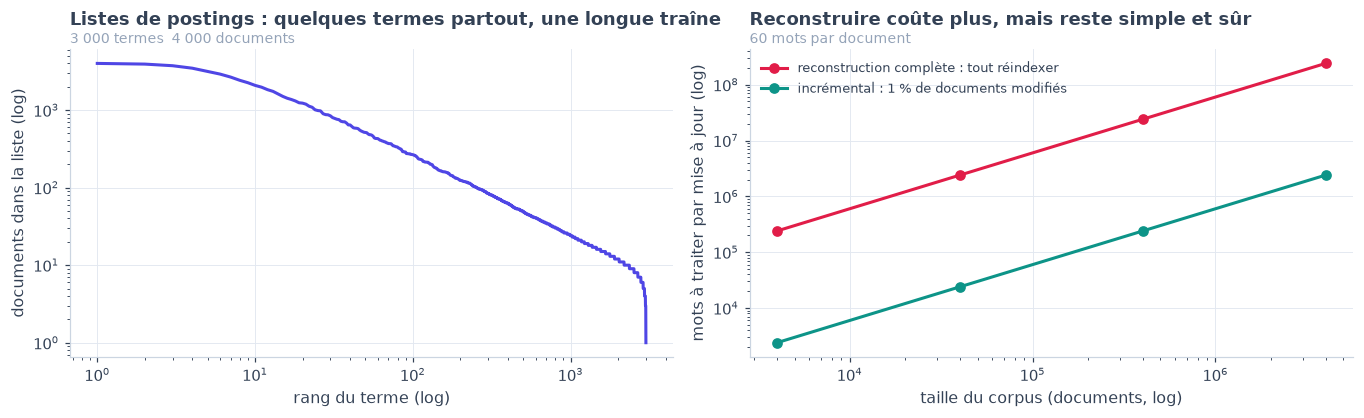

In [5]:
tailles = np.array(sorted((len(v) for v in index.values()), reverse=True))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
axes[0].loglog(np.arange(1, len(tailles) + 1), tailles, color=INDIGO)
axes[0].set_xlabel("rang du terme (log)"); axes[0].set_ylabel("documents dans la liste (log)")
axes[0].set_title("Listes de postings : quelques termes partout, une longue traîne")
subtitle(axes[0], f"{len(index):,} termes, {len(docs):,} documents".replace(",", " "))
# reconstruire tout l'index chaque nuit, ou mettre à jour ?
n_total = np.array([4000, 40_000, 400_000, 4_000_000])
modif = 0.01
axes[1].loglog(n_total, n_total * 60, "o-", color=ROSE, label="reconstruction complète : tout réindexer")
axes[1].loglog(n_total, n_total * 60 * modif, "o-", color=TEAL, label="incrémental : 1 % de documents modifiés")
axes[1].set_xlabel("taille du corpus (documents, log)"); axes[1].set_ylabel("mots à traiter par mise à jour (log)")
axes[1].set_title("Reconstruire coûte plus, mais reste simple et sûr")
subtitle(axes[1], "60 mots par document")
axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Les fichiers d'index produits sont immuables : une fois écrits, on les copie vers les
serveurs de recherche et on bascule. Si les documents changent, on peut relancer tout le
job périodiquement et remplacer l'index entier : coûteux quand peu de documents
changent, mais simple à raisonner (entrée, sortie, rien d'autre). L'alternative est
d'indexer seulement les changements et de fusionner les segments en arrière-plan, comme
Lucene (et comme les arbres LSM du chapitre 4).

> **À retenir.** Un index inversé se construit naturellement par lots : le shuffle sur le
> terme (ou un partitionnement par document) fait tout le travail de regroupement.
> L'index produit est un fichier immuable qu'on publie d'un bloc.

## 3. Construire une base clé-valeur par lots (section *Serving Derived Data*)

Autre sortie typique : une table de recommandations ou de caractéristiques (*features*)
par utilisateur, qu'une application web doit pouvoir lire par clé, en quelques
millisecondes. La tentation : appeler la bibliothèque cliente de la base de production
depuis les tâches du job, et écrire les enregistrements un par un. Le livre explique
pourquoi c'est une mauvaise idée :

1. **lenteur** : une requête réseau par enregistrement est de plusieurs ordres de
   grandeur plus lente que le débit normal d'une tâche de lots ;
2. **surcharge** : des centaines de tâches qui écrivent en parallèle au rythme d'un job de
   lots peuvent écraser la base, et dégrader les lectures du service en production ;
3. **effets de bord visibles** : le job perd sa garantie « tout ou rien ». Une sortie
   partielle est visible avant la fin, et une tâche relancée écrit ses
   enregistrements **deux fois**.

Le deuxième point se quantifie avec la théorie des files d'attente du chapitre
2 : modélisons la base comme une file M/M/1 de capacité 20 000
opérations par seconde, qui sert déjà 8 000 lectures par seconde du site, et ajoutons les
écritures de $k$ tâches de lots à 500 écritures par seconde chacune.

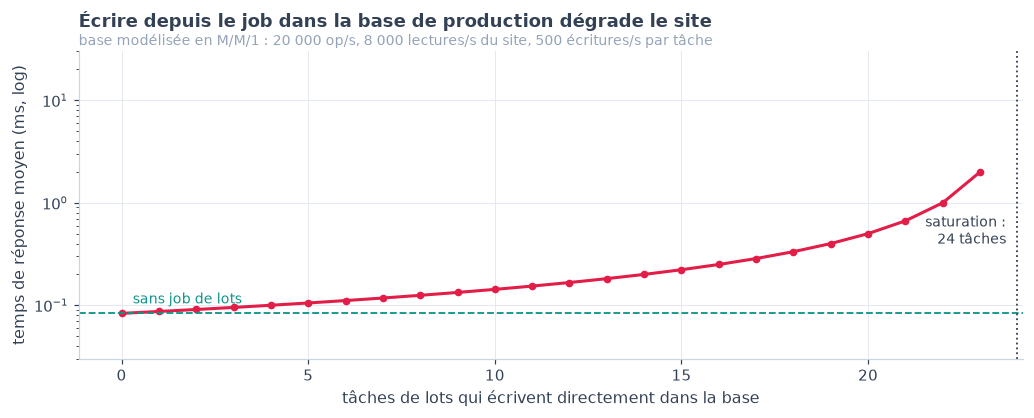

In [6]:
mu, lect = 20_000, 8_000
k = np.arange(0, 26)
charge = lect + 500 * k
rho = charge / mu
lat = np.full(len(k), np.nan)
lat[rho < 1] = 1e3 / (mu - charge[rho < 1])                     # temps de réponse moyen M/M/1 (ms)
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.plot(k, lat, "o-", color=ROSE, ms=4)
ax.axhline(1 / (mu - lect) * 1e3, color=TEAL, ls="--", lw=1.2)
ax.text(0.3, 1 / (mu - lect) * 1e3 * 1.25, "sans job de lots", color=TEAL, fontsize=9)
kmax = (mu - lect) / 500
ax.axvline(kmax, color=SLATE, ls=":", lw=1.2)
ax.text(kmax - 0.3, 0.4, f"saturation :\n{kmax:.0f} tâches", ha="right", fontsize=9, color=SLATE)
ax.set_yscale("log"); ax.set_ylim(0.03, 30)
ax.set_xlabel("tâches de lots qui écrivent directement dans la base"); ax.set_ylabel("temps de réponse moyen (ms, log)")
ax.set_title("Écrire depuis le job dans la base de production dégrade le site")
subtitle(ax, "base modélisée en M/M/1 : 20 000 op/s, 8 000 lectures/s du site, 500 écritures/s par tâche")
plt.tight_layout(); plt.show()

Avec 20 tâches, le temps de réponse des lectures du site est multiplié par 6, avec 22
tâches par 12 ; à 24 tâches, la base sature. Or un job de lots lance volontiers des centaines de tâches.
Le troisième point se vérifie en simulant une tâche qui échoue au milieu et qui est
relancée : sans idempotence, ses premiers enregistrements sont écrits deux fois.

In [7]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE reco (user_id INTEGER, item INTEGER)")          # pas de clé : on empile


def tache(con, lignes, echoue_a=None):
    for i, row in enumerate(lignes):
        if echoue_a is not None and i == echoue_a:
            raise RuntimeError("tâche préemptée")
        con.execute("INSERT INTO reco VALUES (?, ?)", row)


lignes = [(u, (u * 7) % 100) for u in range(1000)]
try:
    tache(con, lignes, echoue_a=600)
except RuntimeError:
    pass
vu_pendant = con.execute("SELECT COUNT(*) FROM reco").fetchone()[0]
tache(con, lignes)                                                        # relance par le framework
total, distinct = con.execute("SELECT COUNT(*), COUNT(DISTINCT user_id) FROM reco").fetchone()
pd.DataFrame({"valeur": [vu_pendant, total, distinct, total - distinct]},
             index=["lignes visibles pendant la panne (sortie partielle)", "lignes après relance",
                    "utilisateurs distincts", "doublons"])

,valeur
lignes visibles pendant la panne (sortie partielle),600
lignes après relance,1600
utilisateurs distincts,1000
doublons,600


**La bonne approche : construire la base dans le job.** Le job écrit lui-même les
fichiers de la base, dans le format que le serveur sait charger, puis on les publie d'un
bloc. Le livre cite les outils d'import en masse (TiDB Lightning, les jobs d'import d'Apache Pinot) et l'API de RocksDB qui ingère directement des fichiers SST construits par un job de lots.
Comme le job a déjà trié par clé (le shuffle !), écrire une **SSTable** est un simple
parcours séquentiel : `B.write_sorted_kv` écrit un fichier trié et un index creux, et
`B.SortedKVFile` le lit par dichotomie. Comparons avec l'écriture enregistrement par
enregistrement dans SQLite (sur disque).

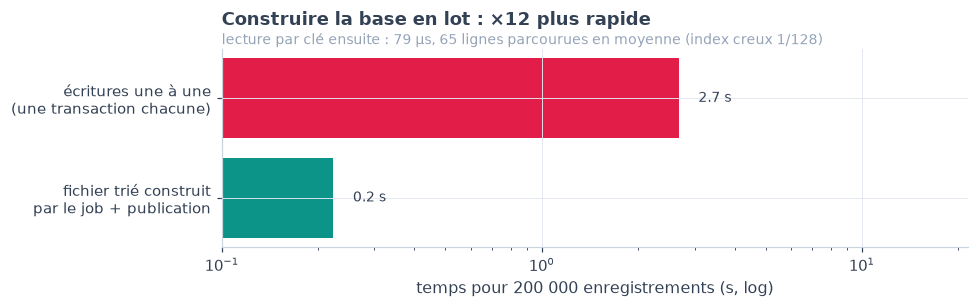

In [8]:
n = 200_000
items = [(f"user:{i:07d}", [int(x) for x in np.random.default_rng(i).integers(0, 10_000, 5)]) for i in range(n)]
# 1) écriture directe, une transaction par enregistrement (le cas d'un client naïf)
path_db = os.path.join(WORK, "prod.db")
con = sqlite3.connect(path_db)
con.execute("CREATE TABLE reco (k TEXT PRIMARY KEY, v TEXT)")
t0 = time.perf_counter()
m_direct = 3000
for k_, v_ in items[:m_direct]:
    con.execute("INSERT INTO reco VALUES (?, ?)", (k_, str(v_)))
    con.commit()
t_direct = (time.perf_counter() - t0) / m_direct * n                     # extrapolé à n
con.close()
# 2) fichier trié construit par le job, puis publication
v_dir = os.path.join(WORK, "kv", "v1")
os.makedirs(v_dir)
t0 = time.perf_counter()
info = B.write_sorted_kv(os.path.join(v_dir, "part-00000"), items, index_every=128)
B.publish_version(os.path.join(WORK, "kv"), v_dir)
t_build = time.perf_counter() - t0
lecteur = B.SortedKVFile(os.path.join(WORK, "kv", "current", "part-00000"))
cles_test = [items[i][0] for i in np.random.default_rng(0).integers(0, n, 2000)]
t0 = time.perf_counter()
for c_ in cles_test:
    assert lecteur.get(c_) is not None
t_get = (time.perf_counter() - t0) / len(cles_test)
fig, ax = plt.subplots(figsize=(9, 2.9))
ax.barh(["écritures une à une\n(une transaction chacune)", "fichier trié construit\npar le job + publication"],
        [t_direct, t_build], color=[ROSE, TEAL])
for i, v in enumerate([t_direct, t_build]):
    ax.text(v * 1.15, i, f"{v:.1f} s", va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlim(0.1, max(t_direct, t_build) * 8); ax.invert_yaxis()
ax.set_xlabel("temps pour 200 000 enregistrements (s, log)")
ax.set_title(f"Construire la base en lot : ×{t_direct / t_build:.0f} plus rapide")
subtitle(ax, f"lecture par clé ensuite : {t_get * 1e6:.0f} µs, {lecteur.lines_scanned / len(cles_test):.0f} lignes parcourues en moyenne (index creux 1/128)")
plt.tight_layout(); plt.show()
lecteur.close()

L'écriture une à une (extrapolée depuis 3 000 enregistrements) paie, pour chaque
enregistrement, une transaction complète : analyse de la requête, mise à jour du B-tree,
validation. Ici le dossier de travail est en mémoire, si bien que la synchronisation
disque est presque gratuite ; sur un vrai disque (de 0,1 à 10 ms par synchronisation),
et plus encore à travers le réseau, l'écart serait d'un à trois ordres de grandeur de
plus. La construction en lot écrit séquentiellement un fichier que personne ne lit
encore, puis le rend visible d'un coup. Pendant la construction, la base
de production ne voit aucune charge ; si le job échoue, rien n'est publié ; si la
nouvelle version est mauvaise, on rebascule sur l'ancienne. La lecture par clé ne
parcourt que quelques dizaines de lignes grâce à l'index creux. La limite de l'approche :
une base reconstruite de zéro se met mal à jour par petits incréments ; d'où des approches hybrides (Venice combine remplacement complet et mises à jour ligne à ligne).

> **À retenir.** N'écrivez pas depuis un job dans la base de production : c'est lent,
> cela la surcharge, et la sortie partielle ou dupliquée devient visible. Construisez la
> base (fichiers triés, index) dans le job, puis publiez-la atomiquement en gardant la
> version précédente.

## 4. ETL et analytique : agrégats préparés contre requêtes ad hoc (sections *Extract-Transform-Load* et *Analytics*)

**ETL.** Extraire des données d'une base de production, les transformer et les charger
dans un entrepôt (chapitre 1) est l'usage le plus répandu du traitement
par lots : filtrer, projeter, convertir sont des travaux « embarrassingly parallel ».
Les ordonnanceurs de workflows relancent les échecs transitoires et signalent les jobs
qui échouent durablement ; les fichiers d'un job raté s'inspectent facilement. Une bonne
pratique : isoler les enregistrements invalides dans un fichier de rebut plutôt que
d'échouer en silence ou de tout arrêter.

In [9]:
rng = np.random.default_rng(3)
brut = pd.DataFrame({"user_id": rng.integers(0, 5000, 50_000), "pays": rng.choice(["FR", "DE", "US", "JP", None], 50_000, p=[.3, .2, .3, .19, .01]),
                     "montant": rng.gamma(2, 30, 50_000).round(2), "jour": rng.integers(0, 90, 50_000)})
brut.loc[rng.choice(50_000, 120, replace=False), "montant"] = -1.0          # montants corrompus
valide = brut.pays.notna() & (brut.montant >= 0)
propre, rebut = brut[valide], brut[~valide]
pd.DataFrame({"lignes": [len(brut), len(propre), len(rebut)]}, index=["extraites", "chargées", "mises au rebut (à inspecter)"])

,lignes
extraites,50000
chargées,49381
mises au rebut (à inspecter),619


**Analytique.** Les analystes interrogent ces données de deux façons : des requêtes
**ad hoc**, qui parcourent les faits bruts pour répondre à une question nouvelle, et des
requêtes sur des **agrégats préparés** (cubes OLAP, *data marts*, chapitre
4), recalculés par un job planifié, qui répondent instantanément aux questions
prévues. Le stockage est souvent un magasin d'objets avec un format de table (Iceberg)
et un catalogue : c'est le *lakehouse*. Comparons le nombre de lignes lues par une
requête de tableau de bord, selon qu'elle lit les faits ou le cube (jour × pays).

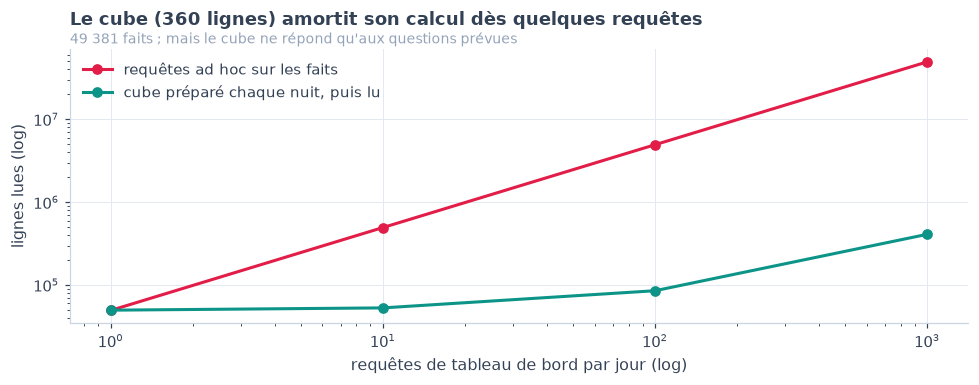

In [10]:
cube = propre.groupby(["jour", "pays"]).montant.agg(["sum", "count"]).reset_index()
n_requetes = np.array([1, 10, 100, 1000])
lignes_adhoc = n_requetes * len(propre)
lignes_cube = len(propre) + n_requetes * len(cube)                       # construire le cube, puis le lire
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.loglog(n_requetes, lignes_adhoc, "o-", color=ROSE, label="requêtes ad hoc sur les faits")
ax.loglog(n_requetes, lignes_cube, "o-", color=TEAL, label="cube préparé chaque nuit, puis lu")
ax.set_xlabel("requêtes de tableau de bord par jour (log)"); ax.set_ylabel("lignes lues (log)")
ax.set_title(f"Le cube ({len(cube)} lignes) amortit son calcul dès quelques requêtes")
subtitle(ax, f"{len(propre):,} faits ; mais le cube ne répond qu'aux questions prévues".replace(",", " "))
ax.legend()
plt.tight_layout(); plt.show()

Le cube ne coûte qu'une lecture des faits par jour et se lit ensuite presque
gratuitement ; il ne sait en revanche répondre qu'aux questions prévues par ses
dimensions. Les deux styles cohabitent, souvent sur le même moteur (SparkSQL, Trino) :
la frontière entre ingénierie des données, analytique et ingénierie applicative
s'estompe, et des pratiques comme le *data mesh* ou les *data contracts* aident chaque
équipe à publier ses propres données.

> **À retenir.** L'ETL et l'analytique sont les usages les plus courants des lots :
> transformations parallèles avec rebut des enregistrements invalides, agrégats préparés
> pour les questions prévues, requêtes ad hoc pour les autres.

## 5. L'apprentissage automatique : préparer des données d'entraînement (section *Machine Learning*)

L'apprentissage automatique consomme énormément de traitement par lots : **feature
engineering** (transformer des données brutes en entrées numériques), **entraînement**
(les données d'entraînement en entrée, les poids du modèle en sortie) et **inférence par
lots** (prédire en masse quand le temps réel n'est pas requis). La préparation des
corpus des grands modèles de langage en est un cas extrême : extraire le texte du HTML,
filtrer les documents de mauvaise qualité, **dédupliquer**, découper en jetons.

La déduplication exacte est un simple regroupement par hachage ; les **quasi-doublons**
(une page recopiée avec un pied de page différent) demandent plus d'astuce. MinHash
résume chaque document par une signature courte telle que la probabilité que deux
signatures coïncident sur une composante vaut leur similarité de Jaccard ; le LSH
découpe la signature en $b$ bandes de $r$ lignes et ne compare que les documents qui
partagent au moins une bande, avec une probabilité $1 - (1 - J^r)^b$. C'est un job de
lots idéal : le calcul des signatures est un map, le regroupement par bande un shuffle.

In [11]:
from ddia import batch_modern as BM

rng = np.random.default_rng(5)
base_docs = list(B.make_documents(300, vocab=4000, words_per_doc=120, seed=7).values())
corpus, origine = [], []
for i, t in enumerate(base_docs):
    corpus.append(t); origine.append(i)
    if i % 5 == 0:                                         # un document sur cinq est recopié avec retouches
        w = t.split()
        for j in rng.choice(len(w), 8, replace=False):
            w[j] = "retouche"
        corpus.append(" ".join(w + ["pied", "de", "page", "copie"])); origine.append(i)
sh = [BM.shingles(t, 3) for t in corpus]
sigs = {i: BM.minhash(s, 128, seed=1) for i, s in enumerate(sh)}
cands = BM.lsh_candidates(sigs, bands=32)
vrais = {(i, j) for i in range(len(corpus)) for j in range(i + 1, len(corpus)) if origine[i] == origine[j]}
confirmes = {p for p in cands if BM.jaccard(sh[p[0]], sh[p[1]]) > 0.5}
n_paires = len(corpus) * (len(corpus) - 1) // 2
pd.DataFrame({"valeur": [len(corpus), n_paires, len(cands), len(vrais), len(confirmes & vrais), len(confirmes - vrais)]},
             index=["documents", "paires possibles", "paires candidates (LSH)", "vrais quasi-doublons",
                    "trouvés (Jaccard > 0,5)", "faux positifs"])

,valeur
documents,360
paires possibles,64620
paires candidates (LSH),60
vrais quasi-doublons,60
"trouvés (Jaccard > 0,5)",60
faux positifs,0


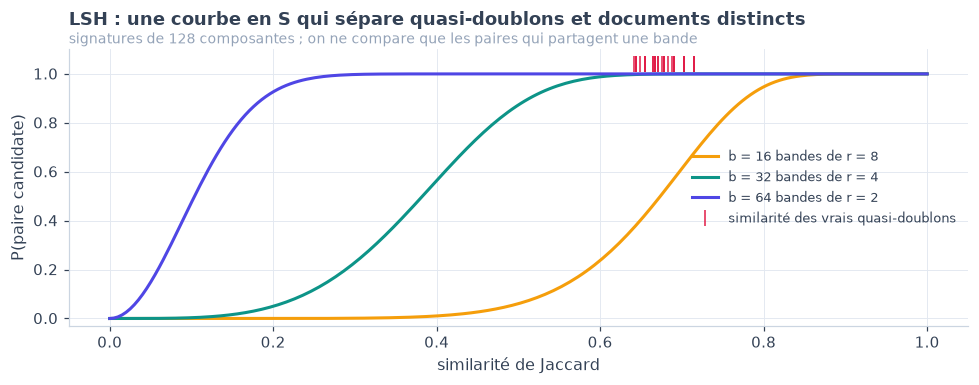

In [12]:
J = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(9, 3.6))
for b_, c in [(16, AMBER), (32, TEAL), (64, INDIGO)]:
    r_ = 128 // b_
    ax.plot(J, 1 - (1 - J ** r_) ** b_, color=c, label=f"b = {b_} bandes de r = {r_}")
jv = [BM.jaccard(sh[i], sh[j]) for i, j in vrais]
ax.plot(jv, np.full(len(jv), 1.04), "|", color=ROSE, ms=10, label="similarité des vrais quasi-doublons")
ax.set_xlabel("similarité de Jaccard"); ax.set_ylabel("P(paire candidate)")
ax.set_ylim(-0.03, 1.1)
ax.set_title("LSH : une courbe en S qui sépare quasi-doublons et documents distincts")
subtitle(ax, "signatures de 128 composantes ; on ne compare que les paires qui partagent une bande")
ax.legend(loc="center right", fontsize=8.5)
plt.tight_layout(); plt.show()

Au lieu de comparer les quelque 64 000 paires possibles, on n'examine qu'une poignée de
candidates, qui contiennent tous les vrais quasi-doublons (leur similarité est élevée,
là où la courbe vaut presque 1). Sur des milliards de pages, c'est la différence entre
l'impossible et un job de quelques heures. Des frameworks spécialisés (Ray, Kubeflow,
Flyte) intègrent ces étapes avec l'entraînement et l'inférence ; les data scientists,
eux, pilotent souvent ces jobs depuis des notebooks.

> **À retenir.** Les lots servent à préparer les données (features, nettoyage,
> déduplication), à entraîner et à inférer en masse. Les quasi-doublons se trouvent sans
> comparer toutes les paires grâce à MinHash et LSH, un calcul qui se découpe en map et
> shuffle.

## 6. Servir les données dérivées à travers un flux (section *Serving Derived Data*)

Plutôt que d'écrire dans la base de production ou de remplacer des fichiers, le job peut
**publier** sa sortie dans un flux (un topic Kafka, chapitre 12) : les moteurs
de recherche, les bases OLAP temps réel (Pinot, Druid) et des magasins dérivés comme
Venice savent consommer un tel flux. Avantages : un flux absorbe très bien les écritures
séquentielles en masse ; il sert de **tampon**, chaque consommateur lisant à son rythme
sans saturer la base ; plusieurs systèmes peuvent consommer la même sortie ; et il peut
servir de frontière de sécurité entre le réseau des lots et celui de la production.

Reste la garantie **tout ou rien** : le consommateur doit garder les données reçues
invisibles (comme une transaction non validée en lecture validée) jusqu'à ce que le job
envoie un message de fin. Simulons un job qui publie 300 000 enregistrements en 60 s, et
une base qui n'en ingère que 2 000 par seconde pour préserver ses lectures.

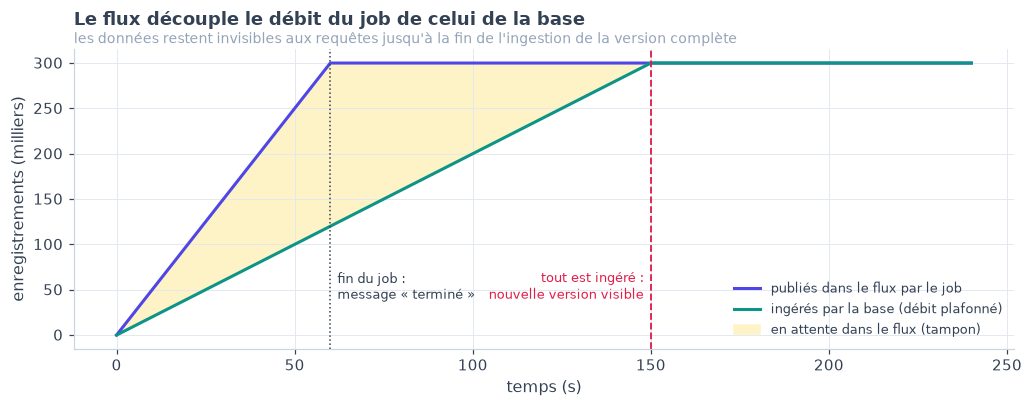

In [13]:
t = np.arange(0, 241)
produit = np.minimum(t * 5000, 300_000)                         # le job publie à 5 000 enr./s
ingere = np.zeros_like(t, dtype=float)
for i in range(1, len(t)):
    ingere[i] = min(produit[i], ingere[i - 1] + 2000)            # la base consomme à 2 000 enr./s max
fin_job, fin_ing = t[produit >= 300_000][0], t[ingere >= 300_000][0]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(t, produit / 1e3, color=INDIGO, label="publiés dans le flux par le job")
ax.plot(t, ingere / 1e3, color=TEAL, label="ingérés par la base (débit plafonné)")
ax.fill_between(t, ingere / 1e3, produit / 1e3, color=LIGHT[AMBER], label="en attente dans le flux (tampon)")
ax.axvline(fin_job, color=SLATE, ls=":", lw=1)
ax.text(fin_job + 2, 40, "fin du job :\nmessage « terminé »", fontsize=8.5)
ax.axvline(fin_ing, color=ROSE, ls="--", lw=1.2)
ax.text(fin_ing - 2, 40, "tout est ingéré :\nnouvelle version visible", fontsize=8.5, ha="right", color=ROSE)
ax.set_xlabel("temps (s)"); ax.set_ylabel("enregistrements (milliers)")
ax.set_title("Le flux découple le débit du job de celui de la base")
subtitle(ax, "les données restent invisibles aux requêtes jusqu'à la fin de l'ingestion de la version complète")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

Le job termine en une minute et libère ses ressources ; la base ingère à son rythme
pendant deux minutes et demie, sans jamais dépasser le débit qui préserve ses lectures,
et ne rend la nouvelle version visible qu'une fois complète.

> **À retenir.** Publier la sortie d'un job dans un flux découple les débits, permet
> plusieurs consommateurs et isole les réseaux ; la garantie tout ou rien exige un
> marqueur de fin et des consommateurs qui n'exposent la version qu'une fois complète.

## Synthèse

- Entrées immuables et sorties regénérées de zéro rendent un job **rejouable** :
  tolérance aux fautes humaines, retour arrière par changement de pointeur.
- Les sorties typiques sont des **structures de données dérivées** : index inversés,
  bases clé-valeur, modèles. On les construit dans le job et on les **publie
  atomiquement**, plutôt que d'écrire enregistrement par enregistrement dans la base de
  production (lent, surchargeant, et sans garantie tout ou rien).
- Les cas d'usage couvrent l'ETL, l'analytique (agrégats préparés et requêtes ad hoc), l'apprentissage automatique (dont la préparation de corpus avec déduplication) et l'alimentation de systèmes en ligne, de préférence via un flux.
- Le chapitre 12 lève l'hypothèse d'une entrée **bornée** : le traitement en
  flux applique les mêmes idées à des données qui n'arrivent jamais à leur fin.

In [14]:
shutil.rmtree(WORK, ignore_errors=True)